In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

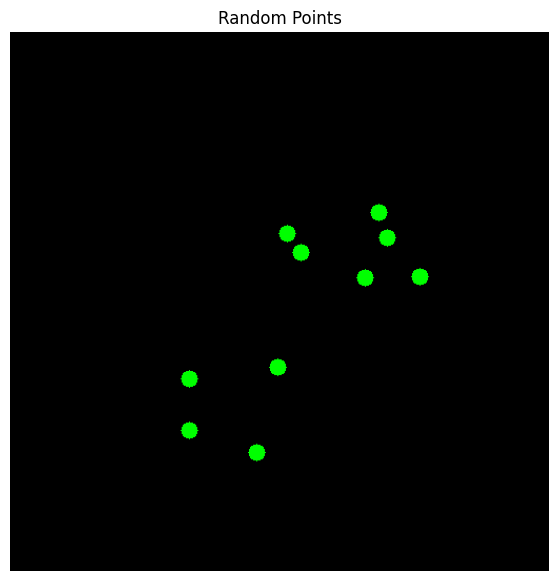

Number Of Random Points: 10


In [2]:
np.random.seed(50)
random_points = np.random.randint(100, 400, 20)
random_points = random_points.reshape(10, 2)

random_points_image = np.zeros((512, 512, 3), dtype=np.uint8)
for point in random_points:
    cv2.circle(random_points_image, (int(point[0]), int(point[1])), 8, (0, 255, 0), -1)

plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(random_points_image, cv2.COLOR_BGR2RGB))
plt.title('Random Points')
plt.axis('off')

plt.show()

print('Number Of Random Points:', len(random_points))

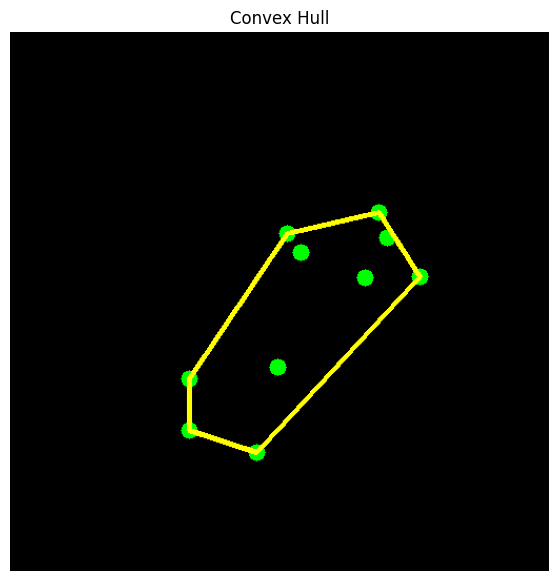

Number Of Points In Convex Hull: 6


In [3]:
random_hull = cv2.convexHull(random_points)
random_hull_image = random_points_image.copy()

cv2.drawContours(random_hull_image, [random_hull], -1, (0, 255, 255), 4)

plt.figure(figsize=(7, 7))
plt.imshow(cv2.cvtColor(random_hull_image, cv2.COLOR_BGR2RGB))
plt.title('Convex Hull')
plt.axis('off')

plt.show()

print('Number Of Points In Convex Hull:', len(random_hull))

In [4]:
uploaded = files.upload()
uploaded_names = list(uploaded.keys())

def find_uploaded_image(keyword, fallback_index):
  matches = [
      name for name in uploaded_names if keyword.lower() in name.lower()
  ]

  if matches:
    return '/content/' + matches[0]

  if fallback_index < len(uploaded_names):
    return '/content/' + uploaded_names[fallback_index]
  raise FileNotFoundError(f'Image Not Found: {keyword}')

star_path = find_uploaded_image('star', 0)
shapes_path = find_uploaded_image('shapes', 1)

print('Star Path:', star_path)
print('Shapes Path:', shapes_path)

Saving shapes.png to shapes.png
Saving star.png to star.png
Star Path: /content/star.png
Shapes Path: /content/shapes.png


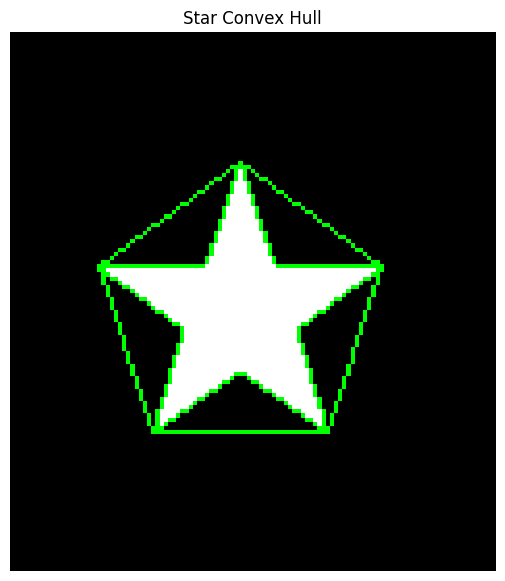

Number Of Star Convex Hull: 1


In [6]:
star_image = cv2.imread(star_path)
if star_image is None:
  raise FileNotFoundError(f'Image Not Found: {star_path}')

star_gray = cv2.cvtColor(star_image, cv2.COLOR_BGR2GRAY)
_, star_thresh = cv2.threshold(star_gray, 127, 255, cv2.THRESH_BINARY)

star_contours, _ = cv2.findContours(star_thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

star_hulls = [cv2.convexHull(contour) for contour in star_contours]
star_result_image = star_image.copy()

cv2.drawContours(star_result_image, star_hulls, -1, (0, 255, 0), 1)

cv2.drawContours(star_result_image, star_contours, -1, (0, 255, 0), 1)

plt.figure(figsize=(7, 7))

plt.imshow(cv2.cvtColor(star_result_image, cv2.COLOR_BGR2RGB))
plt.title('Star Convex Hull')
plt.axis('off')

plt.show()

print('Number Of Star Convex Hull:', len(star_hulls))

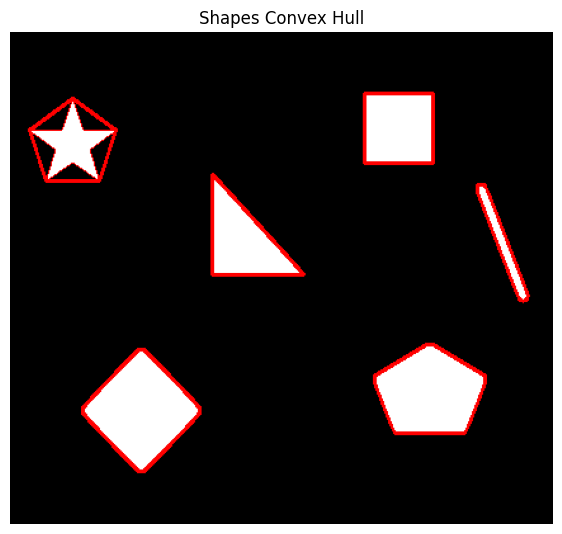

Number Of Shapes Convex Hull: 6


In [7]:
shapes_image = cv2.imread(shapes_path)
if shapes_image is None:
  raise FileNotFoundError(f'Image Not Found: {shapes_path}')

shapes_gray = cv2.cvtColor(shapes_image, cv2.COLOR_BGR2GRAY)
_, shapes_thresh = cv2.threshold(shapes_gray, 127, 255, cv2.THRESH_BINARY)

shapes_contours, _ = cv2.findContours(shapes_thresh, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

shapes_hulls = [cv2.convexHull(contour) for contour in shapes_contours]
shapes_result_image = shapes_image.copy()

cv2.drawContours(shapes_result_image, shapes_hulls, -1, (0, 0, 255), 2)

cv2.drawContours(shapes_result_image, shapes_contours, -1, (0, 0, 255), 1)

plt.figure(figsize=(7, 7))

plt.imshow(cv2.cvtColor(shapes_result_image, cv2.COLOR_BGR2RGB))
plt.title('Shapes Convex Hull')
plt.axis('off')

plt.show()

print('Number Of Shapes Convex Hull:', len(shapes_hulls))

In [9]:
output_images = {
    'random_points_convex_hull.png': random_hull_image,
    'star_convex_hull.png': star_result_image,
    'shapes_convex_hull.png': shapes_result_image
}

for filename, output_image in output_images.items():
  output_path = '/content/' + filename
  cv2.imwrite(output_path, output_image)
  files.download(output_path)
  print('Saved:', filename)
  print(f'Downloaded: {filename}')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved: random_points_convex_hull.png
Downloaded: random_points_convex_hull.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved: star_convex_hull.png
Downloaded: star_convex_hull.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved: shapes_convex_hull.png
Downloaded: shapes_convex_hull.png
